# TerraMesh-Masks Eval playground

In [1]:
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from terramesh.eval_dataset import build_eval_dataset

## Load and visualize some samples

In [2]:
dataset = build_eval_dataset(
    path="https://huggingface.co/datasets/ibm-esa-geospatial/TerraMesh-Masks-Eval/resolve/main/test/", # Default
    modalities=["S2RGB", "BINARY_MASK"], # Select from ["S2L2A", "S2L1C", "S2RGB", "S1_merged", "DEM", "BINARY_MASK"]
    batch_size=4,
)
dataloader  = DataLoader(dataset, batch_size=None)
batch = next(iter(dataloader))
print(batch.keys())

dict_keys(['__key__', 'S2RGB', 'BINARY_MASK', 'class_label', 'class_synonyms'])


In [3]:
# Print shapes of modalities in the first batch
print("Batch shapes:")
print(f"BINARY_MASK: {batch['BINARY_MASK'].shape}")

Batch shapes:
BINARY_MASK: torch.Size([4, 1, 256, 256])


In [4]:
batch['class_label']

['pond', 'industrial area', 'urban park', 'rural residential village']

## Visualizing binary masks with RGB

In [5]:
def plot_sample(rgb, anno, label=None, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(3,3))
    ax.imshow(rgb.permute(1,2,0))
    if len(anno.shape) == 3:
        anno = anno[0]
    anno[:, -1] = anno[:, 0] = anno[-1] = anno[0] = 0  # Set boarder to 0 for plotting contour.

    # overlay mask in red
    ax.imshow(anno, cmap='Reds', vmin=0, vmax=1, alpha=0.3)
    ax.contour(anno, levels=[0.5], colors='red', linewidths=1.5)
    # ax.axis("off") # Keep
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.set_yticks([])
    ax.set_xticks([])
    ax.set_title(label.capitalize())

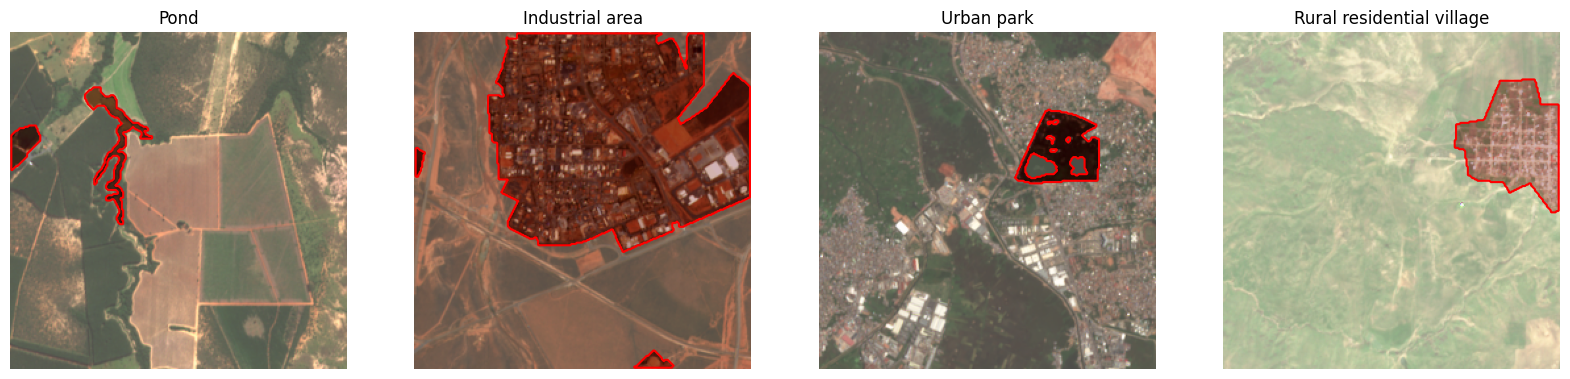

In [6]:
fig, ax = plt.subplots(ncols=4, figsize=(20, 5))
for i in range(4):
    plot_sample(batch["S2RGB"][i], batch["BINARY_MASK"][i], label=batch['class_label'][i], ax=ax[i])
plt.show()